In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, accuracy_score, confusion_matrix, classification_report
import os
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from timeit import default_timer as timer 
from mednet import ResNet10

if torch.cuda.is_available():
    device = "cuda" # Use NVIDIA GPU (if available)
elif torch.backends.mps.is_available():
    device = "mps" # Use Apple Silicon GPU (if available)
else:
    device = "cpu" # Default to CPU if no GPU is available
print(device)

random_state = 12
np.random.seed(random_state)
torch.manual_seed(random_state)

cpu


Now we will train a model that will predict a 'good' VS a 'bad' nodule.

## Initialize model

    @article{chen2019med3d,
        title={Med3D: Transfer Learning for 3D Medical Image Analysis},
        author={Chen, Sihong and Ma, Kai and Zheng, Yefeng},
        journal={arXiv preprint arXiv:1904.00625},
        year={2019}
    }

In [2]:
model = ResNet10()
print(model)

ResNet10(
  (conv1): Conv3d(1, 64, kernel_size=(7, 7, 7), stride=(2, 2, 2), padding=(3, 3, 3), bias=False)
  (bn1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool3d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (bn1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (bn2): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
  )
  (layer2): Sequential(
    (0): BasicBlock(
      (conv1): Conv3d(64, 128, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1), bias=False)
      (bn1): BatchNorm3d(128

### Load pretrained

In [3]:
# Pretrained weights from MedicalNet (Google Drive: MedicalNet_pytorch_files2/pretrain/)
# resnet_10_23dataset.pth = ResNet-10 pretrained on 23 medical datasets
PRETRAINED_PATH = "pretrain_mednet/resnet_10_23dataset.pth"

# weights_only=True: only tensors are loaded, no code from the pickle file is executed
checkpoint = torch.load(PRETRAINED_PATH, map_location="cpu", weights_only=True)
pretrained_dict = checkpoint["state_dict"]

# MedicalNet was trained with nn.DataParallel, so every key starts with "module." (e.g. "module.conv1.weight")
pretrained_dict = {k.replace("module.", "", 1): v for k, v in pretrained_dict.items()}

# Only keep the weights that exist in our model with the same shape
# (our classification head fc is new, so it keeps its random initialization)
model_dict = model.state_dict()
pretrained_dict = {k: v for k, v in pretrained_dict.items() if k in model_dict and v.shape == model_dict[k].shape}

model_dict.update(pretrained_dict)
model.load_state_dict(model_dict)

print(f"Loaded {len(pretrained_dict)}/{len(model_dict)} tensors from {PRETRAINED_PATH}")
print("Not pretrained (random init):", [k for k in model_dict if k not in pretrained_dict])

Loaded 72/74 tensors from pretrain_mednet/resnet_10_23dataset.pth
Not pretrained (random init): ['fc.weight', 'fc.bias']


## Make data ready for training

### Getting the labels

In [4]:
df = pd.read_csv("metadata.csv")

labels = df["label"].values
print(labels)

[1 1 0 ... 1 0 0]


### Splitting the data

We need to split on patients because otherwise we could have data leakage:
<br>
First we take 15% for testing, then we take 15% of the train data for validation
<br>
We can see that the dat is not really skewed

In [5]:
patients = df["patient_id"].unique()

temp_patients, test_patients = train_test_split(patients, test_size=0.15, random_state=random_state)
train_patients, val_patients = train_test_split(temp_patients, test_size=0.15, random_state=random_state)

# get the df with the right patient id
train_df = df[df["patient_id"].isin(train_patients)]
val_df = df[df["patient_id"].isin(val_patients)]
test_df = df[df["patient_id"].isin(test_patients)]

# one patient can have multiple nodules, so multiple samples
train_files, y_train = train_df["patch_path"].values, train_df["label"].values
val_files, y_val = val_df["patch_path"].values, val_df["label"].values
test_files, y_test = test_df["patch_path"].values, test_df["label"].values

print("Patiënts:", len(train_patients), len(val_patients), len(test_patients))
print("Samples:", len(train_files), len(val_files), len(test_files))
print("Aandeel positief:", y_train.mean(), y_val.mean(), y_test.mean())

Patiënts: 631 112 132
Samples: 1860 327 464
Aandeel positief: 0.47419354838709676 0.5412844036697247 0.4892241379310345


Then we load the data:

In [6]:
directory = "C:/Users/huyge/DL_project/data_new"

X_train = np.array([
    np.load(os.path.join(directory, f))
    for f in tqdm(train_files)
])

X_val = np.array([
    np.load(os.path.join(directory, f))
    for f in tqdm(val_files)
])

X_test = np.array([
    np.load(os.path.join(directory, f))
    for f in tqdm(test_files)
])

  0%|          | 0/1860 [00:00<?, ?it/s]

  0%|          | 0/327 [00:00<?, ?it/s]

  0%|          | 0/464 [00:00<?, ?it/s]

To tensors:
<br>
The unsqueeze is because conv3 want: (batch, channels, depth, height, width)

In [7]:
X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
X_val   = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
X_test  = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val   = torch.tensor(y_val, dtype=torch.float32)
y_test  = torch.tensor(y_test, dtype=torch.float32)

### Normalization like MedicalNet

MedicalNet was pretrained on volumes that were z-score normalized per volume (mean 0, std 1).
Our patches are scaled to [0, 1], so we normalize every patch the same way.
Otherwise the pretrained filters see a different distribution than during pretraining.

In [8]:
def zscore(x):
    # mean and std per patch (over depth, height, width), so every patch gets mean 0 and std 1
    mean = x.mean(dim=(2, 3, 4), keepdim=True)
    std = x.std(dim=(2, 3, 4), keepdim=True)
    return (x - mean) / (std + 1e-6) # + 1e-6 to never divide by 0

X_train = zscore(X_train)
X_val   = zscore(X_val)
X_test  = zscore(X_test)
print("Train mean:", X_train.mean().item(), "std:", X_train.std().item())

Train mean: 4.4626335959918606e-10 std: 0.9999895691871643


Making the datasets and dataloaders:

In [9]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

batch_size = 16
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Training loop

### Posssible options to test further:
Todo:
- Scheduler on 

Tried:
- **Data Augmentation** (gave improvement)
- **Dropout higher** (both from 0.2 -> 0.4)
    

In [ ]:
# this function will mirror each sample around the 3 axis
# so every trainings epoch the model will see slightly different data
# this can be done because nodules are rotationsymmertical enough
# we don't have very much data so could make out model more resistent 
# made with help of ClaudeAI
def augment(x):
    for d in (2, 3, 4): # depth, height, width
        mask = torch.rand(x.size(0), device=x.device) < 0.5 # here you will get for every sample a true or false, true means that that samples will be augmented, false means that that sample will stay the same
        x = torch.where(mask.view(-1, 1, 1, 1, 1), x.flip(d), x) # mask.view makes the shape the same as x, torch.where chooses x.flip(d) if the mask is true else x
    return x


EPOCHS = 30
USE_SCHEDULER = False 

loss_fn = nn.BCEWithLogitsLoss()
# Pretrained backbone gets a 10x lower learning rate than the new classification head (fc),
# so the pretrained features are fine-tuned instead of overwritten
LR_BACKBONE = 1e-4
LR_HEAD = 1e-3
head_params = list(model.fc.parameters())
backbone_params = [p for name, p in model.named_parameters() if not name.startswith("fc.")]

optimizer = optim.AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE},
    {"params": head_params, "lr": LR_HEAD},
], weight_decay=1e-2) # AdamW improves upon Adam by decoupling weight decay from the gradient update process, enhancing regularisation and model generalisation (https://blog.prodia.com/post/adam-w-vs-adam-key-differences-and-best-use-cases-for-developers)

model.to(device)

scheduler = optim.lr_scheduler.ReduceLROnPlateau( # Used to lower the learning rate when a metric has stopped improving (in this case the validation verb_top1 and noun_top1 accuracy).
    optimizer,
    mode='min',
    factor=0.5,     # Halve the LR (lr = lr * 0.5)
    patience=2     # Wait 2 epochs before any improvement before lowering the LR
)

history = {"train_loss": [], "val_loss": []} # after every epoch data is set in it here

train_time_start = timer() # Timer starten
for epoch in tqdm(range(EPOCHS)):
    # Training:
    model.train()
    train_loss = 0.0
    for x,y in train_dataloader:
        x = x.to(device)
        x = augment(x) 
        y = y.to(device)

        logits = model(x)
        loss = loss_fn(logits.squeeze(1), y)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # To prevent exploding gradients: if the overall gradient norm exceeds 1, all gradients are scaled down proportionally
        optimizer.step()

        train_loss += loss.item() * x.size(0)
    train_loss /= len(train_dataset)

    # Validation:
    model.eval()
    val_loss = 0.0
    val_probs = []
    with torch.inference_mode():
        for x,y in val_dataloader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            loss = loss_fn(logits.squeeze(1), y)

            val_loss += loss.item() * x.size(0)
            val_probs.append(torch.sigmoid(logits).cpu().numpy()) # to CPU because Sklearn works on RAM, to numpy because Sklearn works with numpy arrays

    val_loss /= len(val_dataset)
    val_auprc = average_precision_score(y_val.numpy(), np.concatenate(val_probs).ravel()) # concatenate groups all the batchs array to one array, .ravel() goes from form (x,1) to (x,) beacause Sklearn expect 1D scores here for binarry classification
    

    if USE_SCHEDULER:
        scheduler.step(val_loss)

    for k, v in zip(history, [train_loss, val_loss]): # zip() koppels every key with every value on that position
        history[k].append(v)

    print(f"Epoch {epoch} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
          f"val AUPRC {val_auprc:.4f} | lr backbone {optimizer.param_groups[0]['lr']:.6f} / head {optimizer.param_groups[1]['lr']:.6f}")
train_time_end = timer()
total_time = train_time_end - train_time_start
print(f"Train time on {str(device)}: {total_time:.3f} seconds")

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 0 | train loss 0.7017 | val loss 0.7358 | val AUPRC 0.6625 | lr backbone 0.000100 / head 0.001000
Epoch 1 | train loss 0.7005 | val loss 0.6874 | val AUPRC 0.6617 | lr backbone 0.000100 / head 0.001000
Epoch 2 | train loss 0.6940 | val loss 0.6989 | val AUPRC 0.6867 | lr backbone 0.000100 / head 0.001000
Epoch 3 | train loss 0.6760 | val loss 0.6960 | val AUPRC 0.6737 | lr backbone 0.000100 / head 0.001000
Epoch 4 | train loss 0.6799 | val loss 0.6782 | val AUPRC 0.6846 | lr backbone 0.000100 / head 0.001000
Epoch 5 | train loss 0.6804 | val loss 0.6870 | val AUPRC 0.6630 | lr backbone 0.000100 / head 0.001000
Epoch 6 | train loss 0.6678 | val loss 0.6840 | val AUPRC 0.6615 | lr backbone 0.000100 / head 0.001000
Epoch 7 | train loss 0.6628 | val loss 0.6519 | val AUPRC 0.7248 | lr backbone 0.000100 / head 0.001000
Epoch 8 | train loss 0.6645 | val loss 0.6620 | val AUPRC 0.6992 | lr backbone 0.000100 / head 0.001000
Epoch 9 | train loss 0.6581 | val loss 0.6401 | val AUPRC 0.7332

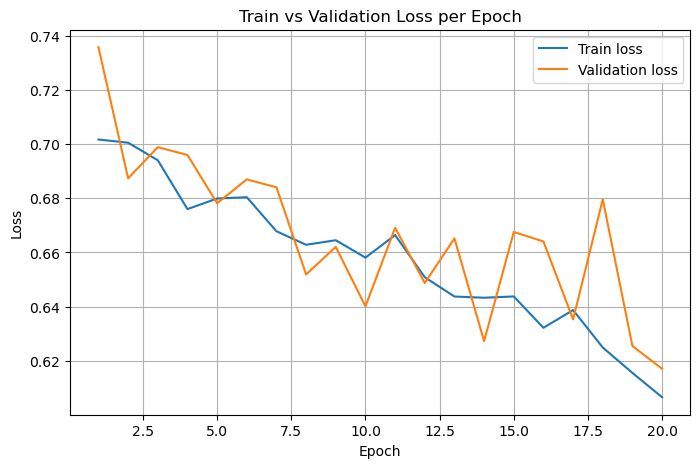

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), history["train_loss"], label="Train loss")
plt.plot(range(1, EPOCHS + 1), history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss per Epoch")
plt.legend()
plt.grid(True)
plt.show()


## Testing

In [12]:
model.eval()

test_probs = []
with torch.inference_mode():
    for x, y in tqdm(test_dataloader):
        x = x.to(device)
        logits = model(x).squeeze(1)
        test_probs.append(torch.sigmoid(logits).cpu().numpy())

y_prob = np.concatenate(test_probs) # (N,)
y_hat  = (y_prob >= 0.5).astype(int) 
y_true = y_test.numpy().astype(int) 

print("Predicted 'Bad':", y_hat.sum())
print("Real 'Bad':", y_true.sum())
print("Shape:", y_true.shape, y_hat.shape)

print("AUPRC: ", average_precision_score(y_true, y_prob))
baseline = y_true.mean()
print(f"Random Baseline ('Bad' %): {baseline:.4f}")
print("Accuracy:", accuracy_score(y_true, y_hat))
print(confusion_matrix(y_true, y_hat))
print(classification_report(y_true, y_hat, target_names=["good", "bad"]))

  0%|          | 0/29 [00:00<?, ?it/s]

Predicted 'Bad': 176
Real 'Bad': 227
Shape: (464,) (464,)
AUPRC:  0.711559575153786
Random Baseline ('Bad' %): 0.4892
Accuracy: 0.6012931034482759
[[170  67]
 [118 109]]
              precision    recall  f1-score   support

        good       0.59      0.72      0.65       237
         bad       0.62      0.48      0.54       227

    accuracy                           0.60       464
   macro avg       0.60      0.60      0.59       464
weighted avg       0.60      0.60      0.60       464

